In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import os 

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Decision_Trees_y_Random_Forest/")

In [3]:
df= pd.read_csv("car_evaluation.csv", sep= ",")
df.head()

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [4]:
col_names= ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df.columns= col_names

In [5]:
df["class"].value_counts()

class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64

In [6]:
df.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

In [7]:
X= df.drop(["class"], axis=1)
y= df["class"]

In [8]:
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size= 0.3, random_state= 42)

In [9]:
X_train.dtypes

buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
dtype: object

In [10]:
import category_encoders as ce 

encoders= ce.OrdinalEncoder(cols= ["buying", "maint", "doors", "persons", "lug_boot", "safety"]) #Convertir variables categoricas a numericas

X_train= encoders.fit_transform(X_train)
X_test= encoders.transform(X_test)

In [11]:
X_train.head()

,buying,maint,doors,persons,lug_boot,safety
1177,1,1,1,1,1,1
585,2,2,2,2,2,2
1551,3,1,2,1,3,2
727,2,1,3,2,1,1
707,2,1,3,3,1,3


In [12]:
tree= DecisionTreeClassifier(max_depth=2, random_state= 42) #Dado que hay pocos datos, se elige poca profundidad
tree.fit(X_train, y_train)

y_train_pred= tree.predict(X_train)
y_test_pred= tree.predict(X_test)

In [13]:
train_accuracy= accuracy_score(y_train,y_train_pred)
test_accuracy= accuracy_score(y_test,y_test_pred)

print("Train accuracy: ", train_accuracy)
print("Test accuracy: ", test_accuracy)

Train accuracy:  0.7673841059602649
Test accuracy:  0.8015414258188824


Text(0.5, 1.0, 'Importancia de los features')

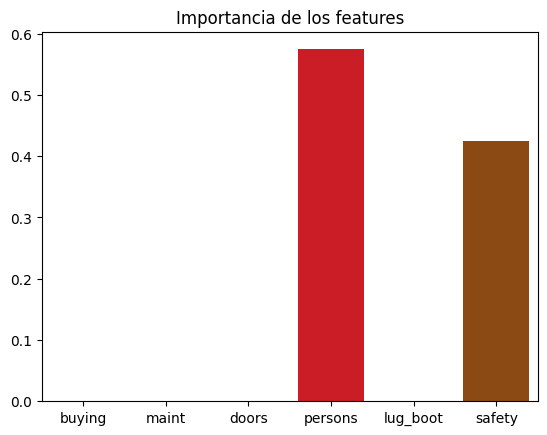

In [14]:
importances= tree.feature_importances_
columns= X.columns

data= pd.DataFrame([importances], columns= columns)

sns.barplot(data, palette= "bright")
plt.title("Importancia de los features")

Train F1 score:  0.7673841059602649
Test F1 score:  0.8015414258188824


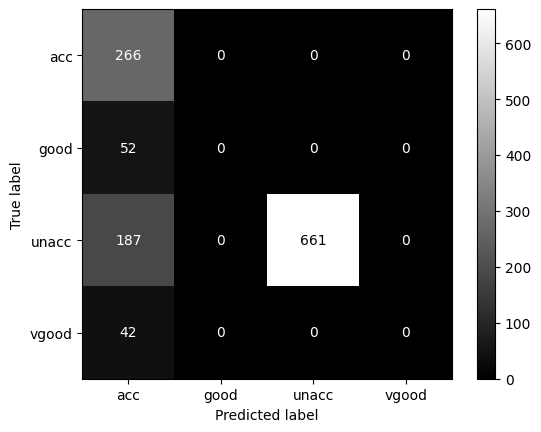

<Figure size 640x480 with 0 Axes>

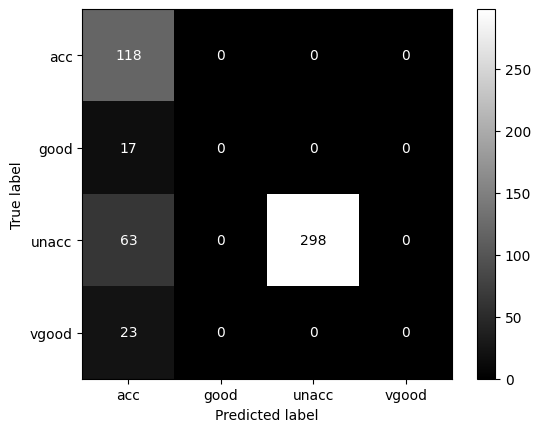

In [15]:
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

#dDado que se trata de un ejercicio de clasificación múltiple, hay que ajustar el parámetro average entre varios tipos
train_f1= f1_score(y_train,y_train_pred, average= "micro") 
test_f1= f1_score(y_test,y_test_pred, average= "micro")

print("Train F1 score: ", train_f1)
print("Test F1 score: ", test_f1)


disp= ConfusionMatrixDisplay.from_predictions(
    y_true= y_train,
    y_pred= y_train_pred,
    cmap= plt.cm.gray,
    normalize= None
)

plt.figure()
disp= ConfusionMatrixDisplay.from_predictions(
    y_true= y_test,
    y_pred= y_test_pred,
    cmap= plt.cm.gray,
    normalize= None
)

#disp.confusion_matrix

In [16]:
from sklearn.metrics import classification_report

target_names= y_train.unique()
results= classification_report(y_train, y_train_pred, target_names= target_names)
print(results)

print("\n")
target_names= y_test.unique()
results= classification_report(y_test, y_test_pred, target_names= target_names)
print(results)

              precision    recall  f1-score   support

       vgood       0.49      1.00      0.65       266
       unacc       0.00      0.00      0.00        52
         acc       1.00      0.78      0.88       848
        good       0.00      0.00      0.00        42

    accuracy                           0.77      1208
   macro avg       0.37      0.44      0.38      1208
weighted avg       0.81      0.77      0.76      1208



              precision    recall  f1-score   support

       unacc       0.53      1.00      0.70       118
         acc       0.00      0.00      0.00        17
       vgood       1.00      0.83      0.90       361
        good       0.00      0.00      0.00        23

    accuracy                           0.80       519
   macro avg       0.38      0.46      0.40       519
weighted avg       0.82      0.80      0.79       519



c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

CON RANDOM FOREST

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf= RandomForestClassifier(n_estimators= 10, random_state= 0)
rf.fit(X_train, y_train)

y_train_pred_rf= rf.predict(X_train)
y_test_pred_rf= rf.predict(X_test)

In [18]:
accuracy_train_rf= accuracy_score(y_train, y_train_pred_rf)
accuracy_test_rf= accuracy_score(y_test, y_test_pred_rf)

print("Train accuracy: ", accuracy_train_rf)
print("Test accuracy: ", accuracy_test_rf)

Train accuracy:  0.9975165562913907
Test accuracy:  0.9113680154142582


<Axes: xlabel='None', ylabel='None'>

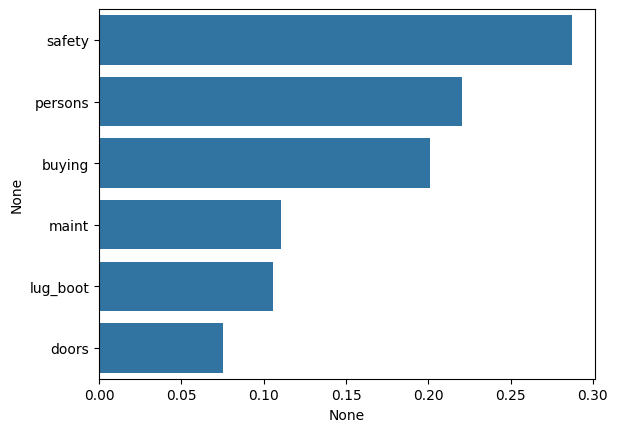

In [24]:
feature_scores= pd.Series(rf.feature_importances_, index= X.columns).sort_values(ascending= False) #Tambien se puede hacer como un df

sns.barplot(x= feature_scores, y= feature_scores.index)

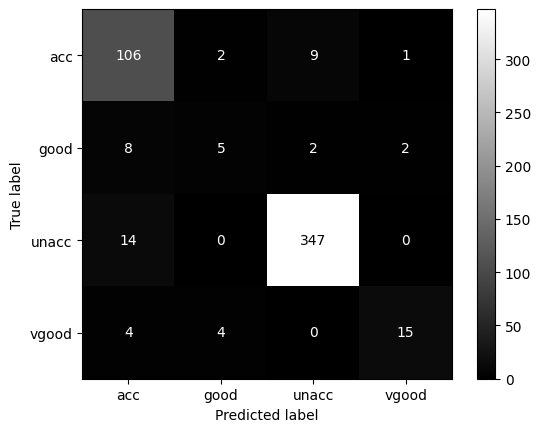

In [25]:
from sklearn.metrics import confusion_matrix

cm= confusion_matrix(y_test, y_test_pred_rf, labels= rf.classes_)
disp= ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= rf.classes_)
disp.plot(cmap="gray")

In [28]:
target_names_rf= y_test.unique()
results_rf= classification_report(y_test, y_test_pred_rf, target_names= target_names_rf)
print(results)

              precision    recall  f1-score   support

       unacc       0.53      1.00      0.70       118
         acc       0.00      0.00      0.00        17
       vgood       1.00      0.83      0.90       361
        good       0.00      0.00      0.00        23

    accuracy                           0.80       519
   macro avg       0.38      0.46      0.40       519
weighted avg       0.82      0.80      0.79       519

